<a href="https://colab.research.google.com/github/ernesto-miguez/Machine-Learning/blob/master/Softmax_collapse.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Softmax Collapse in bfloat16

This notebook demonstrates the **Softmax Collapse** bug described in the paper *"A Fix for Softmax and Cross-Entropy"* by Jonathan T. Barron et al. (Google DeepMind).

When a model's confidence grows and the logit margin $m$ exceeds the precision cliff of `bfloat16` ($\approx 5.5$), standard implementations round the target gradient to zero. This breaks the zero-sum property of softmax gradients and triggers the notorious **"slingshot"** loss spikes in adaptive optimizers like Adam.

Here, we isolate this numerical bug using PyTorch's `autograd` in `bfloat16` and compare it against the stable fix proposed in the paper (`torch.log1p`).

In [29]:
import torch
import torch.nn.functional as F

print("=== OFFICIAL DEMO: Softmax Collapse & Fix (Barron et al.) ===")
print("This script isolates the pure numerical error described in the Google DeepMind paper.\n")

# 1. Define the stable implementation proposed in the paper (based on log1p)
def stable_cross_entropy_fix(logits, target):
    """
    Stable implementation of log-softmax, softmax, and cross-entropy from the paper.
    Uses torch.log1p on relative logit differences (z_j - z_t) to bypass
    the numerical precision cliff.
    """
    z_t = logits.gather(-1, target.unsqueeze(-1))
    diffs = logits - z_t
    mask = torch.arange(logits.size(-1), device=logits.device) == target.unsqueeze(-1)

    # Exclude the target class by replacing it with -inf so its exponential becomes 0
    exp_diffs = torch.exp(torch.where(mask, torch.tensor(-float('inf'), dtype=logits.dtype, device=logits.device), diffs))

    # Exact and numerically stable calculation without decimal loss
    loss = torch.log1p(exp_diffs.sum(dim=-1))
    return loss.mean()

# 2. Create a scenario in bfloat16 format where the margin exceeds the "precision cliff" (~5.5)
# Target class = 0, with a logit of 10.0 vs 0.0 for the other classes.
# Margin m = 10.0 - log(sum(exp(0))) = 10.0 - log(2) ≈ 9.3 (Exceeds the ~5.5 limit in bf16!)
logits_standard = torch.tensor([[10.0, 0.0, 0.0]], dtype=torch.bfloat16, requires_grad=True)
logits_stable = torch.tensor([[10.0, 0.0, 0.0]], dtype=torch.bfloat16, requires_grad=True)
target = torch.tensor([0], dtype=torch.long)

# --- CASE A: Standard Implementation (Native PyTorch / AI Frameworks) ---
loss_std = F.cross_entropy(logits_standard, target)
loss_std.backward()

# --- CASE B: Stable Implementation (Barron et al. Method) ---
loss_stab = stable_cross_entropy_fix(logits_stable, target)
loss_stab.backward()

# 3. Results and Organic Bug Verification
print(f"Analyzed logits (Target class = 10.0, Alternatives = 0.0): {logits_standard.detach().float().numpy()}")
print("-" * 70)
print("COMPUTED GRADIENTS (Derivatives with respect to logits):")
print(f" > Standard Gradient (PyTorch): {logits_standard.grad.float().numpy()}")
print(f"   Sum of standard gradients: {logits_standard.grad.sum().item():.4f}")
print("-" * 70)
print(f" > Stable Gradient (Barron et al.): {logits_stable.grad.float().numpy()}")
print(f"   Sum of stable gradients:   {logits_stable.grad.sum().item():.4f}")
print("-" * 70)

print("\n🔍 TECHNICAL CONCLUSION:")
print("• In the standard version, the gradient of the correct class (index 0) is truncated")
print("  EXACTLY TO 0.0 due to rounding in bfloat16 when the margin exceeds ~5.5.")
print("  This breaks the mathematical property that softmax gradients must sum to zero[cite: 1].")
print("• In the stable version, the gradient is calculated with absolute precision, maintaining")
print("  the mathematical symmetry intact and avoiding the slingshot effect in optimizers like Adam[cite: 1].")

=== OFFICIAL DEMO: Softmax Collapse & Fix (Barron et al.) ===
This script isolates the pure numerical error described in the Google DeepMind paper.

Analyzed logits (Target class = 10.0, Alternatives = 0.0): [[10.  0.  0.]]
----------------------------------------------------------------------
COMPUTED GRADIENTS (Derivatives with respect to logits):
 > Standard Gradient (PyTorch): [[0.000000e+00 4.529953e-05 4.529953e-05]]
   Sum of standard gradients: 0.0001
----------------------------------------------------------------------
 > Stable Gradient (Barron et al.): [[-9.059906e-05  4.529953e-05  4.529953e-05]]
   Sum of stable gradients:   0.0000
----------------------------------------------------------------------

🔍 TECHNICAL CONCLUSION:
• In the standard version, the gradient of the correct class (index 0) is truncated
  EXACTLY TO 0.0 due to rounding in bfloat16 when the margin exceeds ~5.5.
  This breaks the mathematical property that softmax gradients must sum to zero[cite: 1].
•

=== DEMO: Softmax Collapse vs. Barron et al. Stable Fix ===


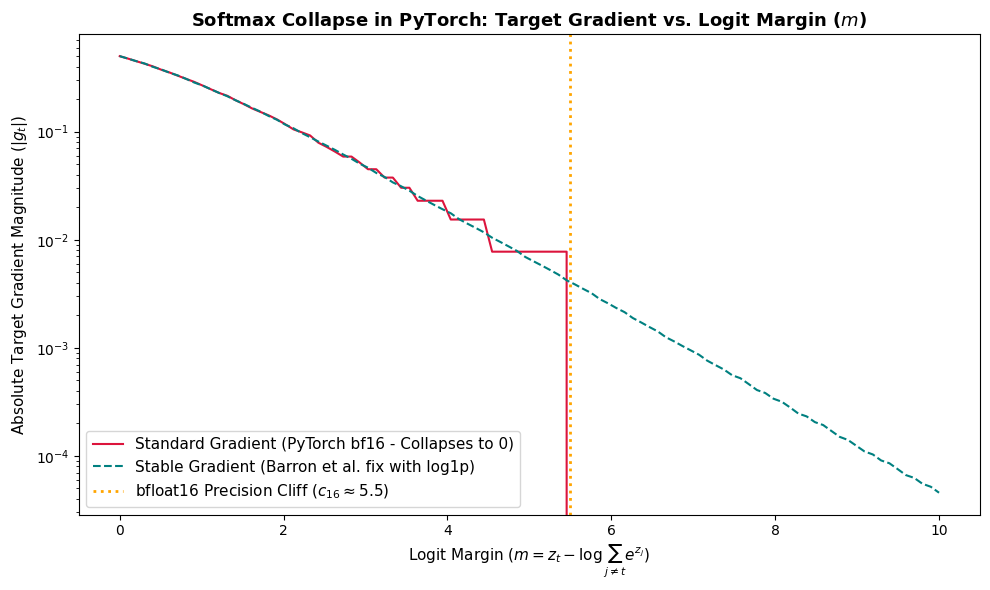

In [33]:
import torch
import matplotlib.pyplot as plt

print("=== DEMO: Softmax Collapse vs. Barron et al. Stable Fix ===")

# 1. Define the stable cross-entropy fix proposed in the paper (using torch.log1p)
def stable_cross_entropy_fix(logits, target):
    """
    Computes numerically stable cross-entropy by formulating log-softmax
    with log1p on relative logit differences, preventing precision loss.
    """
    z_t = logits.gather(-1, target.unsqueeze(-1))
    diffs = logits - z_t
    mask = torch.arange(logits.size(-1), device=logits.device) == target.unsqueeze(-1)

    # Exclude the target class by setting its difference to -inf
    exp_diffs = torch.exp(torch.where(mask, torch.tensor(-float('inf'), dtype=logits.dtype, device=logits.device), diffs))

    loss = torch.log1p(exp_diffs.sum(dim=-1))
    return loss.mean()

# 2. Evaluate target gradients across an increasing range of logit margins (m)
margins = torch.linspace(0.0, 10.0, 100)
grad_stds = []
grad_stabs = []

for m in margins.numpy():
    # Construct synthetic 3-class logits where the target class margin equals 'm'
    val_other = 0.0
    val_target = m + torch.log(torch.tensor(2.0)).item()

    # --- Standard Implementation (PyTorch Native bfloat16) ---
    logits_std = torch.tensor([[val_target, val_other, val_other]], dtype=torch.bfloat16, requires_grad=True)
    target_tensor = torch.tensor([0], dtype=torch.long)

    loss_std = torch.nn.functional.cross_entropy(logits_std, target_tensor)
    loss_std.backward()
    grad_stds.append(abs(logits_std.grad[0, 0].item()))

    # --- Stable Implementation (Barron et al. fix) ---
    logits_stab = torch.tensor([[val_target, val_other, val_other]], dtype=torch.bfloat16, requires_grad=True)

    loss_stab = stable_cross_entropy_fix(logits_stab, target_tensor)
    loss_stab.backward()
    grad_stabs.append(abs(logits_stab.grad[0, 0].item()))


# 3. Plotting the results ( resembling Figure 1a from the paper )
plt.figure(figsize=(10, 6))
plt.plot(margins.numpy(), grad_stds, label='Standard Gradient (PyTorch bf16 - Collapses to 0)', color='crimson', lw=1.5)
plt.plot(margins.numpy(), grad_stabs, label='Stable Gradient (Barron et al. fix with log1p)', color='teal', lw=1.5, linestyle='--')

plt.axvline(x=5.5, color='orange', linestyle=':', lw=2, label='bfloat16 Precision Cliff ($c_{16} \\approx 5.5$)')

plt.title('Softmax Collapse in PyTorch: Target Gradient vs. Logit Margin ($m$)', fontsize=13, fontweight='bold')
plt.xlabel('Logit Margin ($m = z_t - \\log \\sum_{j \\neq t} e^{z_j}$)', fontsize=11)
plt.ylabel('Absolute Target Gradient Magnitude ($|g_t|$)', fontsize=11)
plt.yscale('log')
plt.legend(fontsize=11, loc='lower left')
plt.tight_layout()
plt.show()